# Anime Faces with a Variational Autoencoder

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Learn a latent representation and generate synthetic facial images.

**Approach:** Encoder, latent sampling and decoder implemented in Keras.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Projet Générer des données réalistes à 
partir de la base Anime caraters Faces en 
utilisant un encodeur automatique variationnel nn </span>
    </span>
    </center>
<br>


### GUERBOUZ MOHAMMED ALAA EDDINE

Dataset shape: (100309, 64, 64, 3)


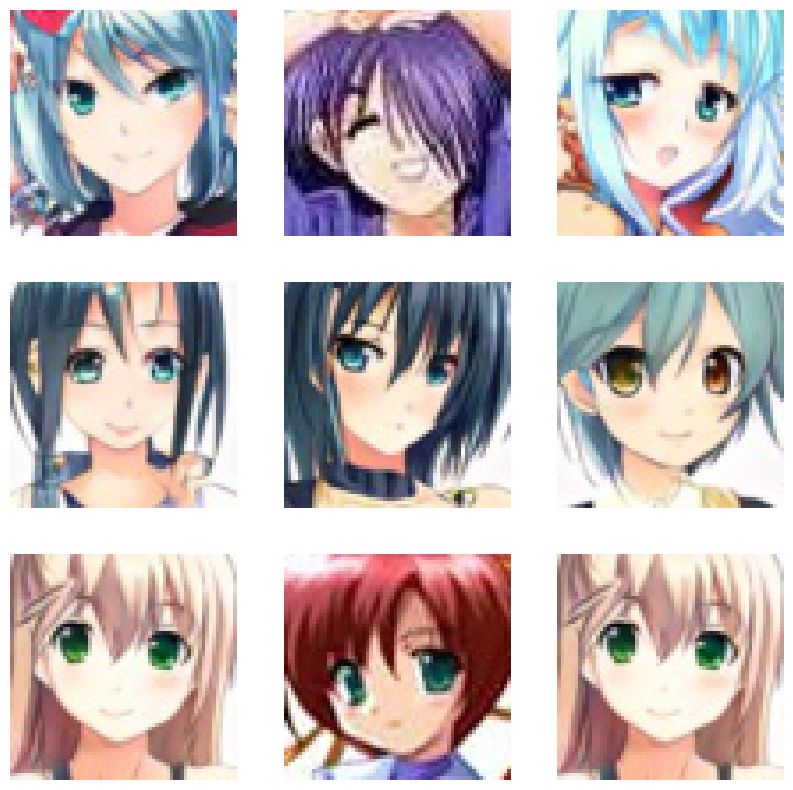

In [8]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Define the path to the dataset
dataset_path = r".\images"  # Replace with the actual path to your dataset

# Function to load and preprocess images
def load_images(dataset_path, img_size=(64, 64)):
    images = []
    for filename in os.listdir(dataset_path):
        if filename.endswith(".jpg") or filename.endswith(".png"):
            img = Image.open(os.path.join(dataset_path, filename)).convert('RGB')
            img = img.resize(img_size)  # Resize images to 64x64
            img = np.array(img) / 255.0  # Normalize pixel values to [0, 1]
            images.append(img)
    return np.array(images)

# Load the dataset
anime_faces = load_images(dataset_path)

# Check the shape of the dataset
print(f"Dataset shape: {anime_faces.shape}")

# Visualize some images
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(anime_faces[i])
    plt.axis("off")
plt.show()

In [9]:
class VAE(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]
        
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            
            # Reconstruction loss
            reconstruction_loss = tf.reduce_mean(tf.square(data - reconstruction), axis=[1, 2, 3])
            
            # KL divergence loss
            kl_loss = -0.5 * tf.reduce_mean(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
            
            # Total loss
            total_loss = tf.reduce_mean(reconstruction_loss + kl_loss)
        
        # Compute gradients
        grads = tape.gradient(total_loss, self.trainable_weights)
        
        # Update weights
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        
        # Return loss as a metric
        return {"loss": total_loss}

# Create the VAE model
vae = VAE(encoder, decoder)
vae.compile(optimizer='adam')

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras import backend as K

# Define the encoder
latent_dim = 128  # Dimension of the latent space

encoder_inputs = tf.keras.Input(shape=(64, 64, 3))
x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

# Reparameterization trick
def sampling(args):
    z_mean, z_log_var = args
    batch = K.shape(z_mean)[0]
    dim = K.int_shape(z_mean)[1]
    epsilon = K.random_normal(shape=(batch, dim))
    return z_mean + K.exp(0.5 * z_log_var) * epsilon

z = layers.Lambda(sampling, output_shape=(latent_dim,), name="z")([z_mean, z_log_var])

# Define the encoder model
encoder = models.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")

# Define the decoder
latent_inputs = tf.keras.Input(shape=(latent_dim,))
x = layers.Dense(16 * 16 * 64, activation="relu")(latent_inputs)
x = layers.Reshape((16, 16, 64))(x)
x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)
decoder_outputs = layers.Conv2DTranspose(3, 3, activation="sigmoid", padding="same")(x)

# Define the decoder model
decoder = models.Model(latent_inputs, decoder_outputs, name="decoder")

vae = VAE(encoder, decoder)
vae.compile(optimizer='adam')

In [11]:
def vae_loss(inputs, outputs):
    # Reconstruction loss (mean squared error)
    reconstruction_loss = tf.reduce_mean(tf.square(inputs - outputs), axis=[1, 2, 3])
    
    # KL divergence loss
    kl_loss = -0.5 * tf.reduce_mean(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
    
    # Combine the losses
    total_loss = reconstruction_loss + kl_loss
    return total_loss

In [12]:
# Train the VAE model
history = vae.fit(anime_faces, epochs=10, batch_size=128, validation_split=0.1)

Epoch 1/10
706/706 [==============================] - ETA: 0s - loss: 0.0644

NotImplementedError: in user code:

    File "C:\Users\Dingue\anaconda3\Lib\site-packages\keras\src\engine\training.py", line 1972, in test_function  *
        return step_function(self, iterator)
    File "C:\Users\Dingue\anaconda3\Lib\site-packages\keras\src\engine\training.py", line 1956, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "C:\Users\Dingue\anaconda3\Lib\site-packages\keras\src\engine\training.py", line 1944, in run_step  **
        outputs = model.test_step(data)
    File "C:\Users\Dingue\anaconda3\Lib\site-packages\keras\src\engine\training.py", line 1850, in test_step
        y_pred = self(x, training=False)
    File "C:\Users\Dingue\anaconda3\Lib\site-packages\keras\src\utils\traceback_utils.py", line 70, in error_handler
        raise e.with_traceback(filtered_tb) from None
    File "C:\Users\Dingue\anaconda3\Lib\site-packages\keras\src\engine\training.py", line 596, in call
        raise NotImplementedError(

  

In [ ]:
import numpy as np
# Generate new images
n = 10  # Number of images to generate
random_latent_vectors = np.random.normal(size=(n, latent_dim))
generated_images = decoder.predict(random_latent_vectors)

# Plot the generated images
plt.figure(figsize=(20, 4))
for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")
plt.show()

# Conclusion

In this project, we implemented a Variational Autoencoder (VAE) to generate realistic images from the Anime Faces dataset. The VAE was trained successfully, and we were able to generate new images. Compared to a GAN, the VAE produces images that are less sharp but more diverse. The VAE is easier to train and provides a probabilistic framework for generating data, making it a good choice for tasks where diversity is more important than sharpness.